# PINN for V: an example of use

This notebook is an example of how to use the value network in `src/mfg/pinn/hjb.py`. The network
solves the HJB equation for **one assumed final mean** $\bar m$ of the population.

- **What it does:** trains the network for a given $\bar m$, and reads from it the value
  $V(t, x)$ and the optimal dollars in the stock, $\pi^*(t, x)$.
- **What it does not do (yet):** no loop on $\bar m$ (the mean that comes out is not fed back),
  no Fokker–Planck, no finite differences, and no checks against other methods. The values of
  $\bar m$ used here are simply made up.

The choices behind the code, and their reasons, are summarised in
`docs/tasks/V_PINN task/Task_PINN_for_V_README_summary.docx`.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Find the repository folder from wherever the notebook runs, and use its source code if the
# package is not installed.
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "configs" / "base.yaml").exists())
try:
    import mfg  # noqa: F401
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))

from mfg.benchmarks import merton_pi, merton_value
from mfg.params import Params
from mfg.pinn.hjb import ValueNetSettings, edge_targets, terminal_targets, train_value_net
from mfg.pinn.nets import pick_device
from mfg.utility import utility

# A harmless notice PyTorch prints the first time it differentiates on a GPU.
warnings.filterwarnings("ignore", message="Attempting to run cuBLAS")

p = Params.from_yaml(ROOT / "configs" / "base.yaml")  # lam = 2, x in [-1, 3], T = 1
print(p)
print("device:", pick_device())

Params(r=0.02, mu=0.08, sigma=0.2, gamma=1.0, lam=2.0, T=1.0, m0_mean=1.0, m0_std=0.2, x_min=-1.0, x_max=3.0)
device: cuda


In [2]:
# Plot style: thin lines, a light grid, and colours chosen by the job they do.
INK, MUTED, BAND = "#0b0b0b", "#898781", "#f0efec"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # different things, always in this order
TIME_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # one blue: light = early, dark = late
LAMBDA_RAMP = ["#f0a070", "#eb6834", "#a8421a"]  # one orange: light = weak penalty, dark = strong
LESS_MORE = LinearSegmentedColormap.from_list("less_more", ["#1c5cab", BAND, "#e34948"])
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.titlesize": 11,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "lines.linewidth": 1.8,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)

## 2. What the network is told

The network learns $v = \log(-V)$ on the rectangle $t \in [0, 1]$, $x \in [-1, 3]$. Inside, it
must satisfy the HJB equation. On three sides it is also told the value of $v$:

- **$t = T$: the final utility.** This is exact: $v_T = \log(-U(x, \bar m))$. It has a kink at
  $x = \bar m$, where the penalty starts, and the kink makes $\pi^*$ jump there.
- **$x = 3$: the Merton value.** From there nobody ends below the mean, so the penalty plays no
  role.
- **$x = -1$: the value of holding the Merton position until $T$.** There is no exact value
  there. This one is slightly below the true value, and close to it. The finite-difference
  solver uses the same one (`benchmarks.py`).

At $t = T$ both edge values equal the final utility, so the three conditions agree at the
corners (the dots below).

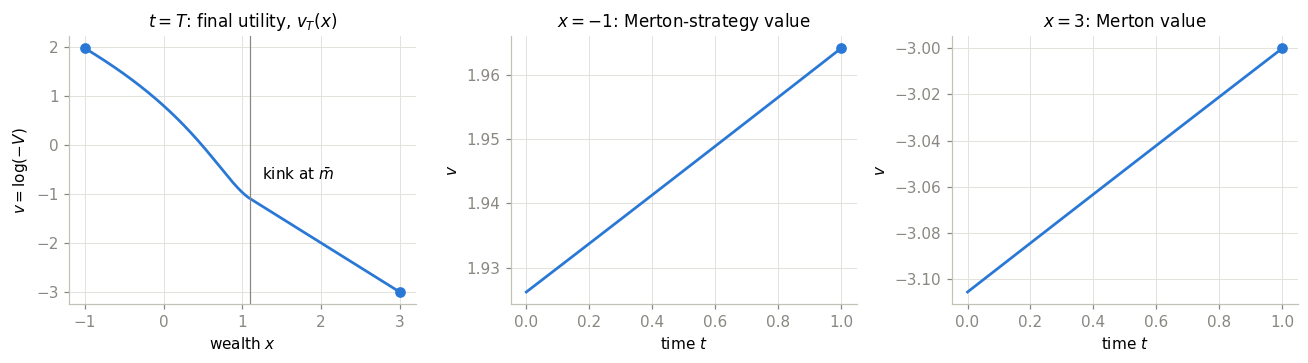

In [3]:
mbar = 1.1  # assumed final mean: the common test case of CONTRIBUTING.md
x = np.linspace(p.x_min, p.x_max, 401)
t = np.linspace(0.0, p.T, 101)
v_T, _, _ = terminal_targets(x, mbar, p)
v_low, v_high = edge_targets(t, mbar, p)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(x, v_T, color=SERIES[0])
axes[0].plot([x[0], x[-1]], [v_T[0], v_T[-1]], "o", color=SERIES[0], ms=6)
axes[0].axvline(mbar, color=MUTED, lw=0.8)
axes[0].annotate(r"kink at $\bar m$", (mbar, np.interp(mbar, x, v_T)), xytext=(8, 12), textcoords="offset points")
axes[0].set(title=r"$t = T$: final utility, $v_T(x)$", xlabel="wealth $x$", ylabel=r"$v = \log(-V)$")
edges = [(axes[1], v_low, "$x = -1$: Merton-strategy value"), (axes[2], v_high, "$x = 3$: Merton value")]
for ax, values, title in edges:
    ax.plot(t, values, color=SERIES[0])
    ax.plot(t[-1], values[-1], "o", color=SERIES[0], ms=6)  # the corner: equal to v_T there
    ax.set(title=title, xlabel="time $t$", ylabel="$v$")
fig.tight_layout()

## 3. Train the network for $\bar m = 1.1$

`train_value_net(p, mbar)` builds a fresh network and trains it in two stages: 10 000 Adam
steps, with new random points at every step, then L-BFGS to polish. It takes about two minutes
on a laptop GPU and longer on a CPU. `ValueNetSettings` holds every choice (network size,
points, steps, coefficients, seed); here we only ask it to print the progress.

In [4]:
sol = train_value_net(p, mbar, ValueNetSettings(print_every=2000))

Adam step      0   loss 6.65e+01


Adam step   2000   loss 1.06e-01


Adam step   4000   loss 8.92e-03


Adam step   6000   loss 2.93e-03


Adam step   8000   loss 2.22e-03


final loss 2.03e-04


### The loss, written out

Training makes one number as small as possible: the loss $L_V$. It adds the four parts plotted
below. Each part is the mean of a squared error over random points, which are drawn again at
every Adam step (L-BFGS uses one fixed draw):

$$
L_V(\theta_V) = \alpha_{\text{equation}}\, L_{\text{equation}} + \alpha_{\text{terminal}}\, L_{\text{terminal}} + \alpha_{\text{slopes}}\, L_{\text{slopes}} + \alpha_{\text{edges}}\, L_{\text{edges}}
$$

Here $\theta_V$ are the weights of the network, $v(t, x)$ is its output, $v = \log(-V)$, and
$v_t$, $v_x$, $v_{xx}$ are its exact derivatives (automatic differentiation). The four
coefficients $\alpha$ are 1 (`coef_equation`, `coef_terminal`, `coef_slopes` and `coef_edges` in
`ValueNetSettings`). The numbers of points are those of the default settings. In the code the
loss is `value_net_loss`, in `hjb.py`.

#### Part 1: the equation

$$
L_{\text{equation}} = \frac{1}{5000} \sum_{i=1}^{5000} \left( \frac{R_{\text{HJB}}(t_i, x_i)}{\kappa^2/2} \right)^2
$$

$$
R_{\text{HJB}} = v_t + r\,x\,v_x - \frac{\kappa^2}{2}\,\frac{v_x^2}{\max\left( v_{xx} + v_x^2,\ 0.05 \right)}
$$

**The points.** 5000 points $(t_i, x_i)$ inside the domain: 4000 uniform on
$[0, 1] \times [-1, 3]$, and 1000 more uniform on $[T - 0.1,\ T] \times [\bar m - 0.3,\ \bar m + 0.3]$,
where $\pi^*$ changes fastest.

**What it measures.** How far the network is from satisfying the HJB equation. With the best
position plugged in, the HJB for $V$ is (repo notes `problem21_hjb_fokker_planck`, Step 6)

$$
V_t + r\,x\,V_x - \frac{\kappa^2}{2}\,\frac{V_x^2}{V_{xx}} = 0
$$

Writing $V = -e^{v}$, so that $V_t = -e^{v} v_t$, $V_x = -e^{v} v_x$ and
$V_{xx} = -e^{v}(v_{xx} + v_x^2)$, and dividing by $-e^{v}$, which is never zero, gives the
equation for $v$:

$$
v_t + r\,x\,v_x - \frac{\kappa^2}{2}\,\frac{v_x^2}{v_{xx} + v_x^2} = 0
$$

$R_{\text{HJB}}$ is its left-hand side, so it is zero exactly where the network solves the
equation.

**Why it is divided by $\kappa^2/2 = 0.045$.** Every term of the equation is of that size, so the
division makes Part 1 of size one, like the other parts. Without it, an error in $v_{xx}$, which
sets $\pi^*$, would barely show. The term with the fraction equals
$(\kappa^2/2)(-v_x)\,\sigma^2\pi^*/(\mu - r)$, about $0.03\,\pi^*$ where $v_x \approx -1$. So an
error of 0.1 in $\pi^*$ would change the undivided residual by only 0.003; after the division it
changes it by 0.067.

**Why the max with 0.05.** The fraction divides by $v_{xx} + v_x^2 = V_{xx}/V$, which is positive
because $V$ is concave. A random network at the start of training can make it zero or negative,
and the max avoids dividing by it. At the trained solution it stays above 0.65 (section 6 prints
its smallest value), so the max plays no role in the result.

#### Part 2: the final value

$$
L_{\text{terminal}} = \frac{1}{1000} \sum_{k=1}^{1000} \big( v(T, x_k) - v_T(x_k) \big)^2
$$

$$
v_T(x) = \log\big( -U(x, \bar m) \big) = \log\left( e^{-\gamma x} + \frac{\lambda}{2} \big( (\bar m - x)^+ \big)^2 \right)
$$

**The points.** 1000 wealths $x_k$ uniform on $[-1, 3]$, at $t = T$.

**What it measures.** At $t = T$ nothing is left to choose, so $V(T, x) = U(x, \bar m)$ and $v$
must equal $v_T$, which is exact (computed with `utility.py`). This is the only part where the
utility, the penalty $\lambda$ and $\bar m$ enter; the equation carries them backward in time.
The equation alone does not fix $v$ (if $v$ solves it, so does $v + 5$): this part and the edges
pick the right solution.

#### Part 3: the final slopes

$$
L_{\text{slopes}} = \frac{1}{K} \sum_{k:\ \lvert x_k - \bar m \rvert > 0.05} \Big[ \big( v_x(T, x_k) - v_T^{\prime}(x_k) \big)^2 + \big( v_{xx}(T, x_k) - v_T^{\prime\prime}(x_k) \big)^2 \Big]
$$

**The points.** The same $x_k$ at $t = T$, except those within 0.05 of $\bar m$. $K$ is how many
are left, about 975 of the 1000.

**The targets** are the exact derivatives of $v_T$:

$$
v_T^{\prime} = \frac{U_x}{U}, \qquad v_T^{\prime\prime} = \frac{U_{xx}}{U} - \left( \frac{U_x}{U} \right)^2
$$

Above $\bar m$, $v_T = -\gamma x$, so $v_T^{\prime} = -\gamma$ and $v_T^{\prime\prime} = 0$.
Below $\bar m$,

$$
v_T^{\prime}(x) = -\frac{\gamma\,e^{-\gamma x} + \lambda\,(\bar m - x)}{e^{-\gamma x} + \frac{\lambda}{2}\,(\bar m - x)^2}
$$

$$
v_T^{\prime\prime}(x) = \frac{\gamma^2 e^{-\gamma x} + \lambda}{e^{-\gamma x} + \frac{\lambda}{2}\,(\bar m - x)^2} - v_T^{\prime}(x)^2
$$

**What it measures, and why.** Whether the slope and the curvature of the network at $t = T$ are
right. $\pi^*$ depends on $v_{xx}$, and matching the value alone does not pin $v_{xx}$ down: a
wiggle $0.001 \sin(20\pi x)$ is invisible in Part 2 but changes $v_{xx}$ by up to 4. At $\bar m$
the curvature jumps, from 0 just above to $\lambda e^{\gamma \bar m} \approx 6.0$ just below (for
$\lambda = 2$ and $\bar m = 1.1$). A smooth network cannot follow that jump, so the points within
0.05 of $\bar m$ are left out.

#### Part 4: the edges

$$
L_{\text{edges}} = \frac{1}{400} \sum_{j=1}^{200} \Big[ \big( v(t_j, x_{\min}) - v_{\text{low}}(t_j) \big)^2 + \big( v(t_j, x_{\max}) - v_{\text{high}}(t_j) \big)^2 \Big]
$$

**The points.** 200 times $t_j$ uniform on $[0, 1]$. Each is used at both edges, $x_{\min} = -1$
and $x_{\max} = 3$, so the mean is over 400 squared errors.

**What it measures.** Whether the network has the right value on the two edges, where the wealth
axis is cut. The targets come from `benchmarks.py` and are shared with the finite-difference
solver (section 2 above shows them; the reasons are in the task summary).

**Upper edge: the Merton value** (`merton_value`), with $\tau = T - t$ the time left:

$$
v_{\text{high}}(t) = \log\big( -V_{\text{Merton}}(t, x_{\max}) \big) = -\gamma\,x_{\max}\,e^{r\tau} - \frac{\kappa^2}{2}\,\tau
$$

**Lower edge: the value of holding the Merton position until $T$** (`merton_strategy_value`),
$v_{\text{low}} = \log(-\mathbb{E}[U(X_T, \bar m)])$. The final wealth $X_T$ of an investor who
starts at $x_{\min}$ at time $t$ and holds the Merton position is normal, with mean $M$ and
standard deviation $S$, so

$$
v_{\text{low}}(t) = \log\left( e^{-\gamma\,x_{\min}\,e^{r\tau} - \kappa^2\tau/2} + \frac{\lambda}{2} \left[ (d^2 + S^2)\,\operatorname{cdf}\left( \frac{d}{S} \right) + d\,S\,\operatorname{pdf}\left( \frac{d}{S} \right) \right] \right)
$$

$$
M = x_{\min}\,e^{r\tau} + \frac{\kappa^2}{\gamma}\,\tau, \qquad S = \frac{\kappa}{\gamma}\sqrt{\tau}, \qquad d = \bar m - M
$$

cdf and pdf are the distribution function and the density of the standard normal. The first term
is minus the Merton value; the bracket is $\mathbb{E}[((\bar m - X_T)^+)^2]$. At $t = T$ both
targets equal $v_T$ at their edge, so Parts 2 and 4 agree at the corners.

The plot shows the four parts during training. A small loss is needed, but it does not
guarantee a good $\pi^*$, which depends on the curvature of $v$. Checking $\pi^*$ is left to later
tasks.

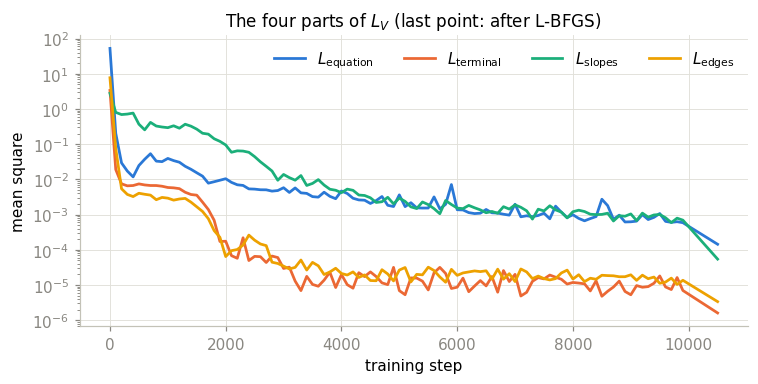

In [5]:
h = sol.history
fig, ax = plt.subplots(figsize=(7, 3.6))
for colour, name in zip(SERIES, ["equation", "terminal", "slopes", "edges"]):
    ax.semilogy(h["step"], h[name], color=colour, label=rf"$L_{{\mathrm{{{name}}}}}$")
ax.set(xlabel="training step", ylabel="mean square", title="The four parts of $L_V$ (last point: after L-BFGS)")
ax.legend(ncol=4, loc="upper right")
fig.tight_layout()

## 4. The value $V$ and the strategy $\pi^*$

`sol.value(t, x)` and `sol.position(t, x)` take NumPy arrays (or numbers) and broadcast like
`t + x`. A single time with an array of wealths gives one curve.

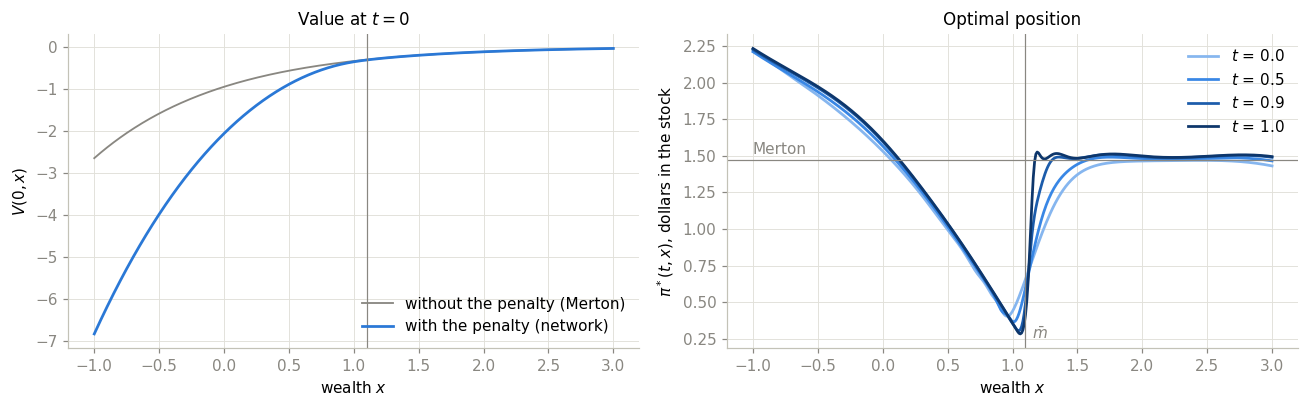

In [6]:
times = [0.0, 0.5, 0.9, 1.0]
fig, (ax_v, ax_pi) = plt.subplots(1, 2, figsize=(12, 3.8))
ax_v.plot(x, merton_value(0.0, x, p), color=MUTED, lw=1.2, label="without the penalty (Merton)")
ax_v.plot(x, sol.value(0.0, x), color=SERIES[0], label="with the penalty (network)")
ax_v.axvline(mbar, color=MUTED, lw=0.8)
ax_v.set(title="Value at $t = 0$", xlabel="wealth $x$", ylabel="$V(0, x)$")
ax_v.legend()
for colour, ti in zip(TIME_RAMP, times):
    ax_pi.plot(x, sol.position(ti, x), color=colour, label=f"$t$ = {ti}")
ax_pi.axhline(merton_pi(0.0, p), color=MUTED, lw=0.8)
ax_pi.text(p.x_min, merton_pi(0.0, p) + 0.04, "Merton", color=MUTED)
ax_pi.axvline(mbar, color=MUTED, lw=0.8)
ax_pi.text(mbar + 0.05, 0.03, r"$\bar m$", color=MUTED, transform=ax_pi.get_xaxis_transform())
ax_pi.set(title="Optimal position", xlabel="wealth $x$", ylabel=r"$\pi^*(t, x)$, dollars in the stock")
ax_pi.legend()
fig.tight_layout()

**Left, the value.** Far above the mean the two curves coincide: the penalty does not reach
those investors. Below the mean the penalty makes $V$ much lower, and more so the further below.

**Right, the strategy.** What to look at:

- **Far above the mean**, $\pi^*$ is the Merton position.
- **Just below the mean** it drops sharply: these investors are afraid of ending below it. At
  $t = T$ the drop is a jump; earlier, the luck still to come smooths it, and the drop starts a
  little above the mean. The small bump just above the mean near $T$ is the smooth network
  overshooting the jump; it is not part of the solution.
- **Far below the mean** it rises above Merton. There the penalty is already being paid, and
  taking more risk is the best chance to catch up.

The map below shows the same for every time at once, as the difference from Merton.

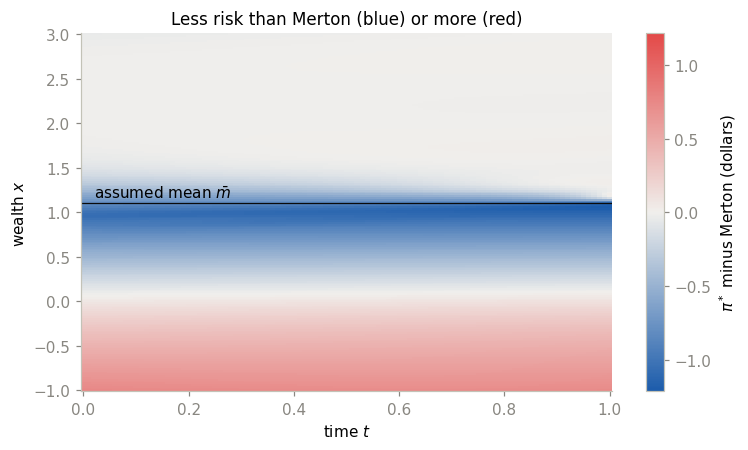

In [7]:
tt, xx = np.meshgrid(np.linspace(0.0, p.T, 101), np.linspace(p.x_min, p.x_max, 201))
deviation = sol.position(tt, xx) - merton_pi(tt, p)
limit = np.abs(deviation).max()

fig, ax = plt.subplots(figsize=(7, 4.2))
mesh = ax.pcolormesh(tt, xx, deviation, cmap=LESS_MORE, norm=Normalize(-limit, limit), shading="auto")
ax.axhline(mbar, color=INK, lw=0.8)
ax.text(0.02, mbar + 0.06, r"assumed mean $\bar m$")
fig.colorbar(mesh, label=r"$\pi^*$ minus Merton (dollars)")
ax.set(title="Less risk than Merton (blue) or more (red)", xlabel="time $t$", ylabel="wealth $x$")
ax.grid(False)
fig.tight_layout()

The same strategy read along time: each line is the position of an investor whose wealth
sits at one level, from $t = 0$ to $T$. The wide grey band is Merton.

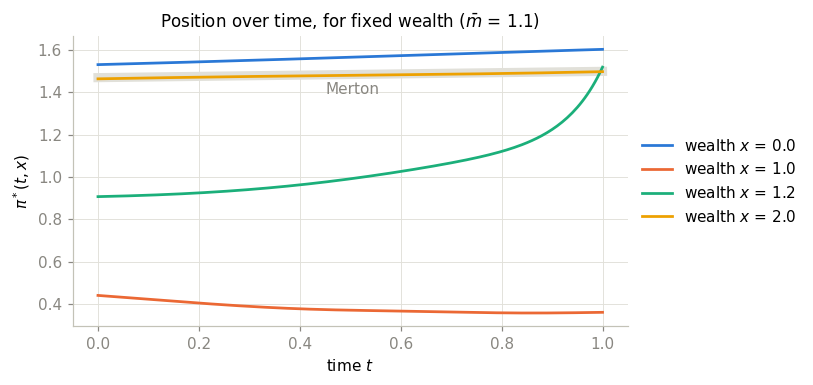

In [8]:
t_line = np.linspace(0.0, p.T, 201)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(t_line, merton_pi(t_line, p), color="#e1e0d9", lw=6, zorder=0)
ax.text(0.45, merton_pi(0.45, p) - 0.09, "Merton", color=MUTED)
for colour, level in zip(SERIES, [0.0, 1.0, 1.2, 2.0]):
    ax.plot(t_line, sol.position(t_line, level), color=colour, label=f"wealth $x$ = {level}")
ax.set(title=r"Position over time, for fixed wealth ($\bar m$ = 1.1)", xlabel="time $t$", ylabel=r"$\pi^*(t, x)$")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()

- **Far above the mean** ($x = 2$): Merton at all times (the line runs along the band).
- **Just above the mean** ($x = 1.2$): below Merton while there is still time to fall under the
  mean, back to Merton at $T$.
- **Just below the mean** ($x = 1$): a small position, which shrinks a little as $T$ approaches.
- **Far below the mean** ($x = 0$): above Merton all along.

## 5. What being able to invest is worth, in sure dollars

$V$ is measured in units of utility, which are hard to read. To turn it into dollars, take the
sure final wealth $c$ that would be just as good as the investor's situation:
$U(c, \bar m) = V(t, x)$.

Not investing at all gives a sure $x\,e^{r(T-t)}$. So the difference $c - x\,e^{r(T-t)}$ is what
the chance to invest is worth to the investor, in sure dollars at $T$. Without the penalty it is
$\kappa^2 T / (2\gamma) = 0.045$ at $t = 0$, the same for everyone. With the penalty it depends on
where the investor stands relative to the mean.

`certainty_equivalent` below finds $c$ by halving an interval, which works because $U$ grows
with $c$. It is a small helper for this notebook only.

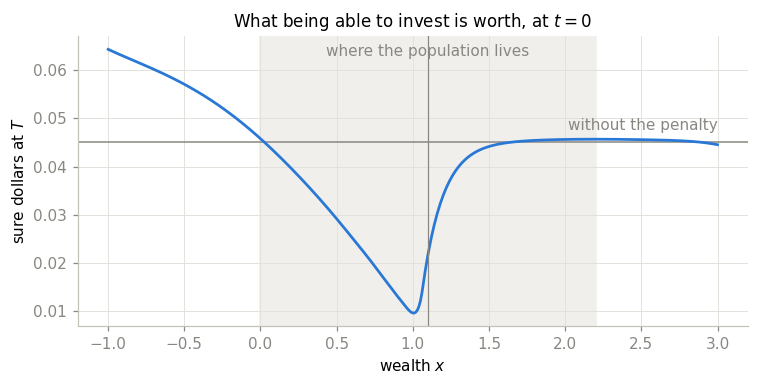

In [9]:
def certainty_equivalent(V, mbar, p):
    """Sure final wealth c with U(c, mbar) = V, found by halving an interval (U grows with c)."""
    low, high = np.full_like(V, -5.0), np.full_like(V, 5.0)
    for _ in range(60):
        mid = 0.5 * (low + high)
        too_low = utility(mid, mbar, p) < V
        low, high = np.where(too_low, mid, low), np.where(too_low, high, mid)
    return 0.5 * (low + high)


worth = certainty_equivalent(sol.value(0.0, x), mbar, p) - x * np.exp(p.r * p.T)
merton_worth = p.kappa**2 * p.T / (2 * p.gamma)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.axvspan(0.0, 2.2, color=BAND, zorder=0)
ax.text(1.1, 0.93, "where the population lives", color=MUTED, ha="center", transform=ax.get_xaxis_transform())
ax.axhline(merton_worth, color=MUTED, lw=1.0)
ax.text(p.x_max, merton_worth + 0.002, "without the penalty", color=MUTED, ha="right", va="bottom")
ax.plot(x, worth, color=SERIES[0])
ax.axvline(mbar, color=MUTED, lw=0.8)
ax.set(title="What being able to invest is worth, at $t = 0$", xlabel="wealth $x$", ylabel="sure dollars at $T$")
fig.tight_layout()

- **Far above the mean** it is 0.045, the same as without the penalty.
- **Near the mean** it falls to about 0.01. These investors barely use the stock: its risk could
  push them below the mean.
- **Far below the mean** it is worth more than without the penalty, about 0.06 at $x = -1$.
  There the stock is the way to catch up.

## 6. Near the edges

The population lives roughly in $x \in [0, 2.2]$ (shaded below). The edges only close the
problem, and two things are worth a look there:

- **$\pi^*$ near the edges.** At $x = 3$ it should be close to Merton. At $x = -1$ the edge
  value is only approximate, so read $\pi^*$ there with care; its error fades inward, before
  reaching the population.
- **$v_{xx} + v_x^2$ must stay positive** ($V$ concave), otherwise $\pi^*$ makes no sense. The
  training divides by it with a safety bound of 0.05, only to get through the first steps,
  while the network is still random. The minimum printed below shows that the trained network
  stays far above the bound.

pi* at x = 3: [1.431 1.465 1.49 ]   Merton: [1.47  1.485 1.497]
smallest v_xx + v_x^2: 0.65 at t = 1.00, x = -1.00 (safety bound 0.05)


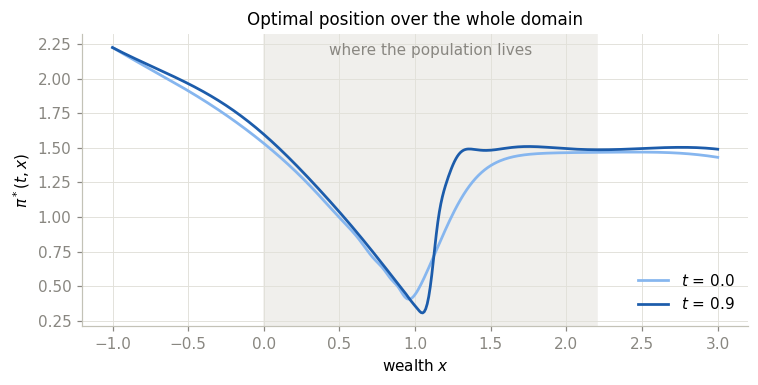

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.axvspan(0.0, 2.2, color=BAND, zorder=0)
ax.text(1.1, 0.93, "where the population lives", color=MUTED, ha="center", transform=ax.get_xaxis_transform())
for colour, ti in zip([TIME_RAMP[0], TIME_RAMP[2]], [0.0, 0.9]):
    ax.plot(x, sol.position(ti, x), color=colour, label=f"$t$ = {ti}")
ax.set(title="Optimal position over the whole domain", xlabel="wealth $x$", ylabel=r"$\pi^*(t, x)$")
ax.legend(loc="lower right")
fig.tight_layout()

times = np.array([0.0, 0.5, 0.9])
print("pi* at x = 3:", np.round(sol.position(times, 3.0), 3), "  Merton:", np.round(merton_pi(times, p), 3))
curvature = sol.concavity(tt, xx)
i = np.unravel_index(curvature.argmin(), curvature.shape)
print(f"smallest v_xx + v_x^2: {curvature[i]:.2f} at t = {tt[i]:.2f}, x = {xx[i]:.2f} (safety bound 0.05)")

## 7. Several made-up means

The network depends on the crowd only through $\bar m$. Here we try two more made-up values.

Each new training starts from the network already trained for $\bar m = 1.1$ (`net=sol.net`).
That network is copied first, so `sol` does not change. Starting close to the answer, 3000 Adam
steps are enough instead of 10 000. The loop of a later task will do the same with the mean that
comes out of the Fokker–Planck equation.

In [11]:
warm = ValueNetSettings(adam_steps=3000, lr_start=3e-4)
solutions = {mbar: sol}
for m in (0.8, 1.4):
    solutions[m] = train_value_net(p, m, warm, net=sol.net)

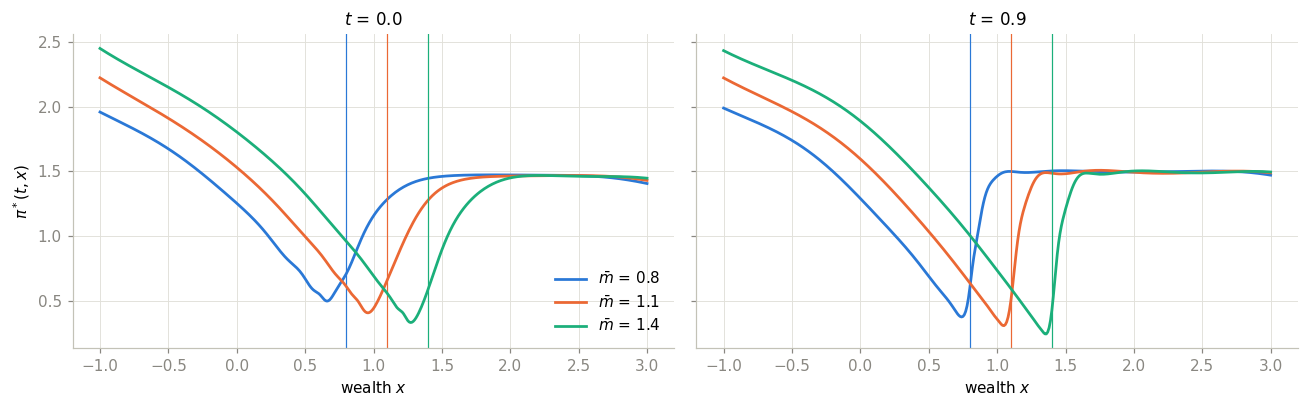

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ti in zip(axes, [0.0, 0.9]):
    for colour, m in zip(SERIES, sorted(solutions)):
        ax.plot(x, solutions[m].position(ti, x), color=colour, label=rf"$\bar m$ = {m}")
        ax.axvline(m, color=colour, lw=0.8)
    ax.set(title=f"$t$ = {ti}", xlabel="wealth $x$")
axes[0].set_ylabel(r"$\pi^*(t, x)$")
axes[0].legend(loc="lower right")
fig.tight_layout()

The dip in $\pi^*$ moves with the assumed mean (the thin vertical lines): investors react to
where they stand relative to $\bar m$. Its depth changes a little, because the exponential part
of the utility depends on wealth itself, not only on the distance to the mean.

Small wiggles of a few hundredths are not real: they are within the accuracy of the network.
Two trainings with different seeds differ by up to about 0.04 in $\pi^*$ where people live.

## 8. How strong the penalty is

Same assumed mean, $\bar m = 1.1$, and the penalty strengths of the project: $\lambda = 1, 2, 5$.
With $\lambda = 0$ there is no penalty and everyone holds the Merton position, which is known
exactly, so it is drawn without training. The two new networks again start from the one for
$\lambda = 2$.

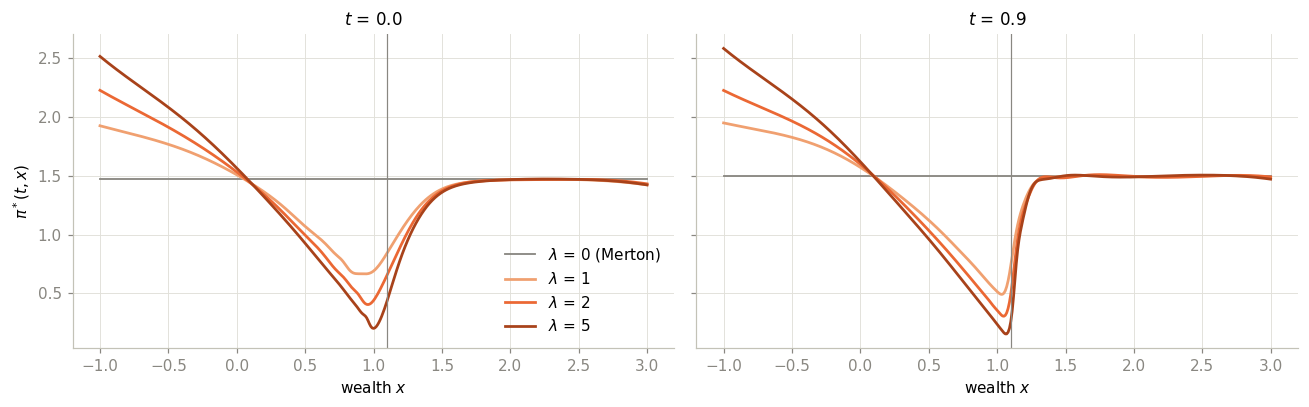

In [13]:
strengths = {p.lam: sol}
for lam in (1.0, 5.0):
    strengths[lam] = train_value_net(p.with_(lam=lam), mbar, warm, net=sol.net)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ti in zip(axes, [0.0, 0.9]):
    ax.plot(x, np.full_like(x, merton_pi(ti, p)), color=MUTED, lw=1.2, label=r"$\lambda$ = 0 (Merton)")
    for colour, lam in zip(LAMBDA_RAMP, sorted(strengths)):
        ax.plot(x, strengths[lam].position(ti, x), color=colour, label=rf"$\lambda$ = {lam:g}")
    ax.axvline(mbar, color=MUTED, lw=0.8)
    ax.set(title=f"$t$ = {ti}", xlabel="wealth $x$")
axes[0].set_ylabel(r"$\pi^*(t, x)$")
axes[0].legend(loc="lower right")
fig.tight_layout()

Switching the penalty on ($\lambda = 1$) already creates the dip below the mean. A stronger
penalty makes it deeper, but each increase changes less: at $t = T$, just below the mean, the
exact position is 0.37 with $\lambda = 1$, 0.21 with $\lambda = 2$ and 0.09 with $\lambda = 5$.
Far below the mean the opposite happens: the stronger the penalty, the further above Merton the
position goes.

All the curves cross Merton at about the same wealth, $x = \bar m - 1/\gamma = 0.1$. At $t = T$
this is exact for every $\lambda$. At that distance below the mean, the penalty changes the slope
and the curvature of the utility in the same proportion. Their ratio, which sets $\pi^*$, stays
Merton's.

## 9. Cheat sheet

| Call | What it gives |
|---|---|
| `train_value_net(p, mbar, settings=None, net=None)` | a trained `ValueNetSolution` |
| `sol.value(t, x)` | $V(t, x)$ |
| `sol.position(t, x)` | $\pi^*(t, x)$, the dollars in the stock |
| `sol.residual(t, x)` | HJB residual (divided by $\kappa^2/2$); near 0 where the equation holds |
| `sol.concavity(t, x)` | $v_{xx} + v_x^2 = V_{xx}/V$; must be positive |
| `sol.history` | the loss parts during training |
| `ValueNetSettings(...)` | every choice: network size, points, steps, coefficients, seed, device |
| `terminal_targets(x, mbar, p)`, `edge_targets(t, mbar, p)` | what the network is told at $t = T$ and at the edges |

Inputs are NumPy arrays or numbers, and they broadcast like `t + x`.